In [1]:
from pathlib import Path
import zipfile
import matplotlib.pyplot as plt
from satpy import Scene
from satpy.readers.core.grouping import group_files  # se non esiste nella tua versione, ignora
from pyresample import create_area_def

RAW = Path("../data/raw")
FCI_DIR = RAW / "EO_EUM_DAT_0662"  
LI_DIR = RAW / "EO_EUM_DAT_0686"

for d in (FCI_DIR, LI_DIR):
    files = sorted(d.glob("*"))
    print(d.name, len(files), "files")
    for f in files[:5]:
        print("  ", f.name, f"{f.stat().st_size/1e6:.1f} MB")

EO_EUM_DAT_0662 11 files
   W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260720120324_IDPFI_OPE_20260720120007_20260720120939_N__O_0073_0000 0.0 MB
   W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260720120324_IDPFI_OPE_20260720120007_20260720120939_N__O_0073_0000.zip 1018.9 MB
   W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260720121337_IDPFI_OPE_20260720121007_20260720121939_N__O_0074_0000 0.0 MB
   W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260720121337_IDPFI_OPE_20260720121007_20260720121939_N__O_0074_0000.zip 1018.5 MB
   W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260720122316_IDPFI_OPE_20260720122007_20260720122939_N__O_0075_0000 0.0 MB
EO_EUM_DAT_0686 16 files
   W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+LI-2-AF--FD--x-x--ARC-x_C_EUMT_20260720120028_L2PF_OPE_20260720115000_20260720120000_N__O_0072_0000 0.0 MB
   W_XX-EUMETSAT-Da

In [2]:
for d in (FCI_DIR, LI_DIR):
    for z in d.glob("*.zip"):
        out = d / z.stem
        if out.exists():
            continue
        if not zipfile.is_zipfile(z):
            print("NOT A ZIP, skipped:", z.name)
            continue
        with zipfile.ZipFile(z) as zf:
            zf.extractall(out)
        print("extracted", out.name)

fci_files = sorted(str(p) for p in FCI_DIR.rglob("*.nc"))
li_files = sorted(str(p) for p in LI_DIR.rglob("*.nc"))
print(len(fci_files), "FCI .nc |", len(li_files), "LI .nc")

NOT A ZIP, skipped: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20260720123310_IDPFI_OPE_20260720123007_20260720123939_N__O_0076_0000.zip
205 FCI .nc | 16 LI .nc


In [3]:
fci = Scene(filenames=fci_files[:40], reader="fci_l1c_nc") 
print(fci.available_dataset_names())
print(fci.start_time, fci.end_time)

['ir_105', 'ir_105_earth_sun_distance', 'ir_105_index_map', 'ir_105_pixel_quality', 'ir_105_platform_altitude', 'ir_105_subsatellite_latitude', 'ir_105_subsatellite_longitude', 'ir_105_subsolar_latitude', 'ir_105_subsolar_longitude', 'ir_105_sun_satellite_distance', 'ir_105_swath_direction', 'ir_105_swath_number', 'ir_105_time', 'ir_123', 'ir_123_earth_sun_distance', 'ir_123_index_map', 'ir_123_pixel_quality', 'ir_123_platform_altitude', 'ir_123_subsatellite_latitude', 'ir_123_subsatellite_longitude', 'ir_123_subsolar_latitude', 'ir_123_subsolar_longitude', 'ir_123_sun_satellite_distance', 'ir_123_swath_direction', 'ir_123_swath_number', 'ir_123_time', 'ir_133', 'ir_133_earth_sun_distance', 'ir_133_index_map', 'ir_133_pixel_quality', 'ir_133_platform_altitude', 'ir_133_subsatellite_latitude', 'ir_133_subsatellite_longitude', 'ir_133_subsolar_latitude', 'ir_133_subsolar_longitude', 'ir_133_sun_satellite_distance', 'ir_133_swath_direction', 'ir_133_swath_number', 'ir_133_time', 'ir_38', 

In [4]:
# 4. Griglia comune sull'Italia (lat/lon per l'esplorazione; per il training ne sceglieremo una equal-area)
area = create_area_def(
    "italy", "EPSG:4326",
    area_extent=[6.6, 36.5, 18.8, 47.1], resolution=0.02, units="degrees",
)
print(area.shape)

channels = ['ir_105', 'ir_105_earth_sun_distance', 'ir_105_index_map', 'ir_105_pixel_quality', 'ir_105_platform_altitude', 'ir_105_subsatellite_latitude', 'ir_105_subsatellite_longitude', 'ir_105_subsolar_latitude', 'ir_105_subsolar_longitude', 'ir_105_sun_satellite_distance', 'ir_105_swath_direction', 'ir_105_swath_number', 'ir_105_time', 'ir_123', 'ir_123_earth_sun_distance', 'ir_123_index_map', 'ir_123_pixel_quality', 'ir_123_platform_altitude', 'ir_123_subsatellite_latitude', 'ir_123_subsatellite_longitude', 'ir_123_subsolar_latitude', 'ir_123_subsolar_longitude', 'ir_123_sun_satellite_distance', 'ir_123_swath_direction', 'ir_123_swath_number', 'ir_123_time', 'ir_133', 'ir_133_earth_sun_distance', 'ir_133_index_map', 'ir_133_pixel_quality', 'ir_133_platform_altitude', 'ir_133_subsatellite_latitude', 'ir_133_subsatellite_longitude', 'ir_133_subsolar_latitude', 'ir_133_subsolar_longitude', 'ir_133_sun_satellite_distance', 'ir_133_swath_direction', 'ir_133_swath_number', 'ir_133_time', 'ir_38', 'ir_38_earth_sun_distance', 'ir_38_index_map', 'ir_38_pixel_quality', 'ir_38_platform_altitude', 'ir_38_subsatellite_latitude', 'ir_38_subsatellite_longitude', 'ir_38_subsolar_latitude', 'ir_38_subsolar_longitude', 'ir_38_sun_satellite_distance', 'ir_38_swath_direction', 'ir_38_swath_number', 'ir_38_time', 'ir_87', 'ir_87_earth_sun_distance', 'ir_87_index_map', 'ir_87_pixel_quality', 'ir_87_platform_altitude', 'ir_87_subsatellite_latitude', 'ir_87_subsatellite_longitude', 'ir_87_subsolar_latitude', 'ir_87_subsolar_longitude', 'ir_87_sun_satellite_distance', 'ir_87_swath_direction', 'ir_87_swath_number', 'ir_87_time', 'ir_97', 'ir_97_earth_sun_distance', 'ir_97_index_map', 'ir_97_pixel_quality', 'ir_97_platform_altitude', 'ir_97_subsatellite_latitude', 'ir_97_subsatellite_longitude', 'ir_97_subsolar_latitude', 'ir_97_subsolar_longitude', 'ir_97_sun_satellite_distance', 'ir_97_swath_direction', 'ir_97_swath_number', 'ir_97_time', 'nir_13', 'nir_13_earth_sun_distance', 'nir_13_index_map', 'nir_13_pixel_quality', 'nir_13_platform_altitude', 'nir_13_subsatellite_latitude', 'nir_13_subsatellite_longitude', 'nir_13_subsolar_latitude', 'nir_13_subsolar_longitude', 'nir_13_sun_satellite_distance', 'nir_13_swath_direction', 'nir_13_swath_number', 'nir_13_time', 'nir_16', 'nir_16_earth_sun_distance', 'nir_16_index_map', 'nir_16_pixel_quality', 'nir_16_platform_altitude', 'nir_16_subsatellite_latitude', 'nir_16_subsatellite_longitude', 'nir_16_subsolar_latitude', 'nir_16_subsolar_longitude', 'nir_16_sun_satellite_distance', 'nir_16_swath_direction', 'nir_16_swath_number', 'nir_16_time', 'nir_22', 'nir_22_earth_sun_distance', 'nir_22_index_map', 'nir_22_pixel_quality', 'nir_22_platform_altitude', 'nir_22_subsatellite_latitude', 'nir_22_subsatellite_longitude', 'nir_22_subsolar_latitude', 'nir_22_subsolar_longitude', 'nir_22_sun_satellite_distance', 'nir_22_swath_direction', 'nir_22_swath_number', 'nir_22_time', 'vis_04', 'vis_04_earth_sun_distance', 'vis_04_index_map', 'vis_04_pixel_quality', 'vis_04_platform_altitude', 'vis_04_subsatellite_latitude', 'vis_04_subsatellite_longitude', 'vis_04_subsolar_latitude', 'vis_04_subsolar_longitude', 'vis_04_sun_satellite_distance', 'vis_04_swath_direction', 'vis_04_swath_number', 'vis_04_time', 'vis_05', 'vis_05_earth_sun_distance', 'vis_05_index_map', 'vis_05_pixel_quality', 'vis_05_platform_altitude', 'vis_05_subsatellite_latitude', 'vis_05_subsatellite_longitude', 'vis_05_subsolar_latitude', 'vis_05_subsolar_longitude', 'vis_05_sun_satellite_distance', 'vis_05_swath_direction', 'vis_05_swath_number', 'vis_05_time', 'vis_06', 'vis_06_earth_sun_distance', 'vis_06_index_map', 'vis_06_pixel_quality', 'vis_06_platform_altitude', 'vis_06_subsatellite_latitude', 'vis_06_subsatellite_longitude', 'vis_06_subsolar_latitude', 'vis_06_subsolar_longitude', 'vis_06_sun_satellite_distance', 'vis_06_swath_direction', 'vis_06_swath_number', 'vis_06_time', 'vis_08', 'vis_08_earth_sun_distance', 'vis_08_index_map', 'vis_08_pixel_quality', 'vis_08_platform_altitude', 'vis_08_subsatellite_latitude', 'vis_08_subsatellite_longitude', 'vis_08_subsolar_latitude', 'vis_08_subsolar_longitude', 'vis_08_sun_satellite_distance', 'vis_08_swath_direction', 'vis_08_swath_number', 'vis_08_time', 'vis_09', 'vis_09_earth_sun_distance', 'vis_09_index_map', 'vis_09_pixel_quality', 'vis_09_platform_altitude', 'vis_09_subsatellite_latitude', 'vis_09_subsatellite_longitude', 'vis_09_subsolar_latitude', 'vis_09_subsolar_longitude', 'vis_09_sun_satellite_distance', 'vis_09_swath_direction', 'vis_09_swath_number', 'vis_09_time', 'wv_63', 'wv_63_earth_sun_distance', 'wv_63_index_map', 'wv_63_pixel_quality', 'wv_63_platform_altitude', 'wv_63_subsatellite_latitude', 'wv_63_subsatellite_longitude', 'wv_63_subsolar_latitude', 'wv_63_subsolar_longitude', 'wv_63_sun_satellite_distance', 'wv_63_swath_direction', 'wv_63_swath_number', 'wv_63_time', 'wv_73', 'wv_73_earth_sun_distance', 'wv_73_index_map', 'wv_73_pixel_quality', 'wv_73_platform_altitude', 'wv_73_subsatellite_latitude', 'wv_73_subsatellite_longitude', 'wv_73_subsolar_latitude', 'wv_73_subsolar_longitude', 'wv_73_sun_satellite_distance', 'wv_73_swath_direction', 'wv_73_swath_number', 'wv_73_time']
fci.load(channels)
fci_it = fci.resample(area, resampler="nearest")

(530, 610)


/opt/anaconda3/envs/eumetsat12/lib/python3.12/site-packages/satpy/readers/fci_l1c_nc.py:593: RuntimeWarning: invalid value encountered in cast
  return lut[block.astype("uint16")]


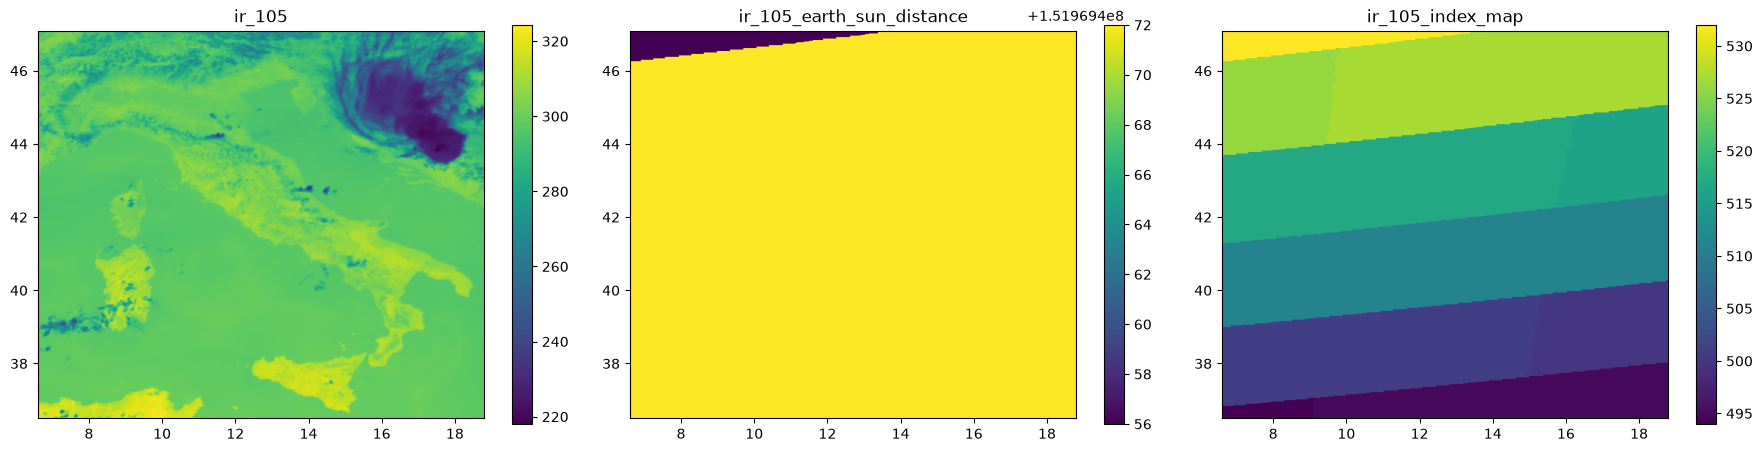

In [5]:
# 5. Plot dei canali FCI
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, ch in zip(axes, channels):
    data = fci_it[ch].values
    im = ax.imshow(data, extent=[6.6, 18.8, 36.5, 47.1], origin="upper")
    ax.set_title(ch); plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()

In [11]:
# 6. LI: file BODY, poi solo quello dello stesso ciclo dell'immagine FCI
li_files = sorted(str(p) for p in LI_DIR.rglob("*CHK-BODY*.nc"))
print(len(li_files), "LI BODY files")

t0 = fci.start_time.strftime("%Y%m%d%H%M%S")   # 20260720120000
t1 = fci.end_time.strftime("%Y%m%d%H%M%S")     # 20260720121000
li_match = [f for f in li_files if f"_{t0}_{t1}_" in Path(f).name]
print("LI del ciclo", t0, "->", [Path(f).name[-60:] for f in li_match])
assert len(li_match) == 1, li_match

li = Scene(filenames=li_match, reader="li_l2_nc")
li.load(["flash_accumulation"])
print(li["flash_accumulation"].shape)   # atteso: (5568, 5568)
print(li.start_time, li.end_time)        # atteso: 12:00 - 12:10

8 LI BODY files
LI del ciclo 20260720120000 -> ['027_L2PF_OPE_20260720120000_20260720121000_N__O_0073_0001.nc']
(5568, 5568)
2026-07-20 12:00:00 2026-07-20 12:10:00


min/max: 0.002 54.679
pixel con fulmini: 2884 su 323300


Text(0.5, 1.0, 'IR 10.5 + LI flash_accumulation (rosso)')

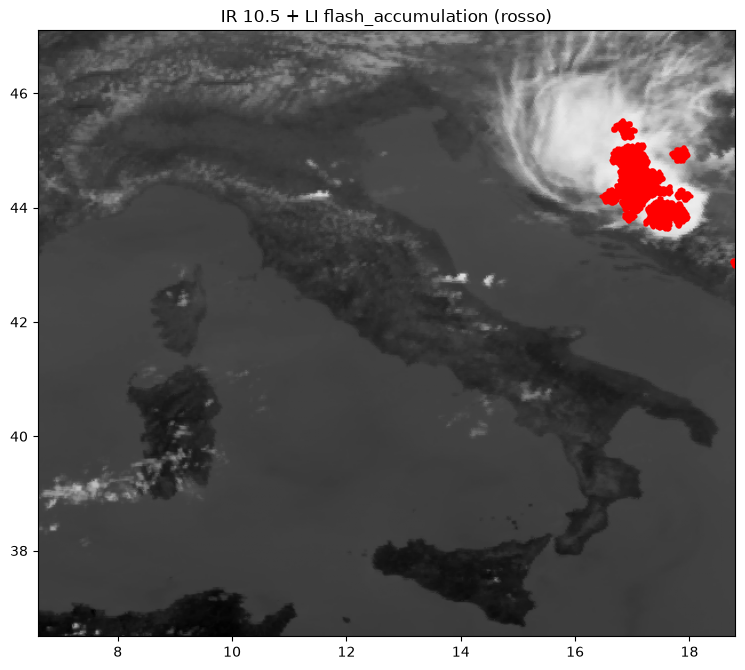

In [12]:
# 7. Resample sulla griglia comune e statistiche
li_it = li.resample(area, resampler="nearest")      # se si lamenta, prova radius_of_influence=8000
flash = li_it["flash_accumulation"].values

import numpy as np
print("min/max:", np.nanmin(flash), np.nanmax(flash))
print("pixel con fulmini:", int((flash > 0).sum()), "su", flash.size)

fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(fci_it["ir_105"].values, extent=[6.6, 18.8, 36.5, 47.1], origin="upper", cmap="gray_r")
ys, xs = (flash > 0).nonzero()
ax.scatter(6.6 + xs * 0.02, 47.1 - ys * 0.02, s=4, c="red")
ax.set_title("IR 10.5 + LI flash_accumulation (rosso)")